In [1]:
from binance.client import Client as bnb_client
from datetime import datetime
import pandas as pd
import statsmodels.api as sm
import numpy as np
import requests
import time
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
ticker_data = requests.get("https://api.binance.com/api/v3/ticker/24hr").json()

In [3]:

# Convert the API response to a DataFrame
ticker_data = pd.DataFrame(ticker_data)

# Convert volume to numeric values
ticker_data["quoteVolume"] = pd.to_numeric(
    ticker_data["quoteVolume"],
    errors="coerce"
)

top_symbols = (
    ticker_data[ticker_data["symbol"].str.endswith("USDT")]
    .sort_values("quoteVolume", ascending=False)
    .head(1000)["symbol"]
    .tolist()
)

In [4]:
def get_all_klines(symbol, interval, start_date, end_date):
    
    url = "https://api.binance.com/api/v3/klines"

    columns = [
        'open_time',
        'open',
        'high',
        'low',
        'close',
        'volume',
        'close_time',
        'quote_volume',
        'trades',
        'taker_buy_base',
        'taker_buy_quote',
        'ignore'
    ]

    start_time = int(pd.Timestamp(start_date, tz='UTC').timestamp() * 1000)
    end_time = int(pd.Timestamp(end_date, tz='UTC').timestamp() * 1000)

    if interval.endswith("M")==False:
        interval_time = int(pd.Timedelta(interval).total_seconds() * 1000)

    all_data = []

    while start_time < end_time:
            # Convert dates to milliseconds
        if interval.endswith("M"):
            start_time = int(pd.Timestamp(start_date, tz='UTC').timestamp() * 1000)
        params = {
            'symbol': symbol,
            'interval': interval,
            'startTime': start_time,
            'endTime': end_time,
            'limit': 1000
        }

        response = requests.get(url, params=params)
        response.raise_for_status()

        batch = response.json()

        # Stop when there is no more data
        if not batch:
            break

        # Add this batch to our collection
        all_data.extend(batch)

        # Last candle's opening timestamp
        last_open_time = batch[-1][0]
        if interval.endswith("M"):
            start_date = pd.Timestamp(start_date)
            months = int(interval[:-1]) 
            start_date += pd.DateOffset(months=months)
        # Move to the next millisecond to avoid duplicates
        else:
            start_time = last_open_time + interval_time

        print(f"{symbol}: downloaded {len(all_data)} candles")

        # If fewer than 1000 were returned, we reached the end
        if len(batch) < 1000:
            break

        # Optional: be polite to the API
        time.sleep(0.1)

    # Combine everything into ONE DataFrame
    df = pd.DataFrame(all_data, columns=columns)

    # Remove any possible duplicate timestamps
    df = df.drop_duplicates(subset='open_time')

    # Convert timestamps
    df['open_time'] = pd.to_datetime(
        df['open_time'],
        unit='ms',
        utc=True
    )

    df['close_time'] = pd.to_datetime(
        df['close_time'],
        unit='ms',
        utc=True
    )

    # Convert numeric columns
    for col in ['open', 'high', 'low', 'close', 'volume']:
        df[col] = pd.to_numeric(df[col])

    return df

In [5]:
def get_prices(t_interval, start_date, end_date, until):
    
    symbols = top_symbols[:until]

    url = "https://api.binance.com/api/v3/klines"

    columns = [
        'open_time', 'open', 'high', 'low', 'close',
        'volume', 'close_time', 'quote_volume',
        'trades', 'taker_buy_base', 'taker_buy_quote',
        'ignore'
    ]

    # -------------------------------------------------
    # 1. Download prices
    # -------------------------------------------------

    data = {}

    for symbol in symbols:
        df = get_all_klines(symbol, t_interval, start_date, end_date)
        df.columns = columns
        data[symbol] = df
        

    # -------------------------------------------------
    # 2. Construct price and return matrices
    # -------------------------------------------------
    
    # Use open_time as index so all assets align by time
    vol = pd.concat(
        {
            symbol: data[symbol].set_index('open_time')['volume']
            for symbol in symbols
        },
        axis=1
    )

    px = pd.concat(
            {
                symbol: data[symbol].set_index('open_time')['close']
                for symbol in symbols
            },
            axis=1
        )

    vol.to_pickle(f'crypto_{until}_{t_interval}_{start_date}_{end_date}_vol.pk')
    px.to_pickle(f'crypto_{until}_{t_interval}_{start_date}_{end_date}_px.pk')

    return vol,px

In [6]:
def activity(t_interval, start_date, end_date,until):
    filename = find_existing_file(t_interval, start_date, end_date,until)
    
    if filename is not None:
        print(f"Using existing data: {filename}")
        vol = pd.read_pickle(filename).loc[start_date:end_date]
        px = pd.read_pickle(f"crypto_{until}_{t_interval}_{start_date}_{end_date}_px.pk").loc[start_date:end_date]
    else:
        print("Downloading data...")
        vol, px = get_prices(t_interval, start_date, end_date,until)
    
    z_scores = z_score(vol, px)
    return z_scores
    

In [7]:
def find_existing_file(t_interval, start_date, end_date,until):
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    pattern = f"crypto_{until}_{t_interval}_*_vol.pk"

    for path in Path(".").glob(pattern):
        try:
            # crypto_{interval}_{start}_{end}_vol.pk
            parts = path.stem.split("_")

            file_start = pd.Timestamp(parts[3])
            file_end = pd.Timestamp(parts[4])

            # Does this file completely cover the requested period?
            if file_start <= start_date and file_end >= end_date:
                return path

        except (ValueError, IndexError):
            continue

    return None

In [8]:
def plot_signal(df, signal):
    fig, ax = plt.subplots(4,1,figsize=(20, 16))
    name_i=['Activity','Returns','Sign Activity','Return Activity']
    for i in range(4):
        ax[i].plot(
                signal[i].index,
                signal[i]
        )
        # One major tick per month
        ax[i].xaxis.set_major_locator(
            mdates.YearLocator()
        )

        ax[i].xaxis.set_major_formatter(
            mdates.DateFormatter('%Y')
        )

        # --------------------------------------------------
        # Minor axis: every 3 months
        # --------------------------------------------------
        ax[i].xaxis.set_minor_locator(
            mdates.MonthLocator(bymonth=[1, 4, 7, 10])
        )

        ax[i].xaxis.set_minor_formatter(
            mdates.DateFormatter('%b')
        )

        # Make major year labels larger
        ax[i].tick_params(
            axis='x',
            which='major',
            labelsize=11,
            pad=15
        )

        # Smaller month labels
        ax[i].tick_params(
            axis='x',
            which='minor',
            labelsize=8,
            pad=3
        )

        ax[i].set_xlabel("Date")
        ax[i].set_ylabel(f"Signal {i+1}")
        ax[i].set_title(name_i[i])

        ax[i].grid(
            axis='x',
            which='major',
            alpha=0.3
        )
    
    plt.tight_layout()
    plt.show()

In [9]:
def z_score(df,px):
    vol_data=df
    vol_prev=vol_data.rolling(min_periods=50,window=500)
    z=(vol_data-vol_prev.mean().shift(1))/vol_prev.std().shift(1)
    ret_data=px.pct_change()
    signal_a = z.mean(axis=1)
    signal_b = ret_data.mean(axis=1)
    signal_c = z.mean(axis=1)*np.sign(ret_data.mean(axis=1))
    signal_d = z.mean(axis=1)*ret_data.mean(axis=1)
    signal=[signal_a, signal_b, signal_c, signal_d]
    plot_signal(df, signal)
    return z
    

In [13]:
filename_px = f"crypto_1000_1d_2017-01-01_2026-09-14_px.pk"
filename_vol = f"crypto_1000_1d_2017-01-01_2026-09-14_vol.pk"
px = pd.read_pickle(filename_px)
vol = pd.read_pickle(filename_vol)
z = z_score(vol,px)

FileNotFoundError: [Errno 2] No such file or directory: 'crypto_1000_1d_2017-01-01_2026-09-14_vol.pk'

USDCUSDT: downloaded 1000 candles
USDCUSDT: downloaded 2000 candles
USDCUSDT: downloaded 3000 candles
USDCUSDT: downloaded 4000 candles
USDCUSDT: downloaded 5000 candles
USDCUSDT: downloaded 6000 candles
USDCUSDT: downloaded 7000 candles
USDCUSDT: downloaded 8000 candles
USDCUSDT: downloaded 8737 candles
BTCUSDT: downloaded 1000 candles
BTCUSDT: downloaded 2000 candles
BTCUSDT: downloaded 3000 candles
BTCUSDT: downloaded 4000 candles
BTCUSDT: downloaded 5000 candles
BTCUSDT: downloaded 6000 candles
BTCUSDT: downloaded 7000 candles
BTCUSDT: downloaded 8000 candles
BTCUSDT: downloaded 8737 candles
ETHUSDT: downloaded 1000 candles
ETHUSDT: downloaded 2000 candles
ETHUSDT: downloaded 3000 candles
ETHUSDT: downloaded 4000 candles
ETHUSDT: downloaded 5000 candles
ETHUSDT: downloaded 6000 candles
ETHUSDT: downloaded 7000 candles
ETHUSDT: downloaded 8000 candles
ETHUSDT: downloaded 8737 candles
ZECUSDT: downloaded 1000 candles
ZECUSDT: downloaded 2000 candles
ZECUSDT: downloaded 3000 candles
Z

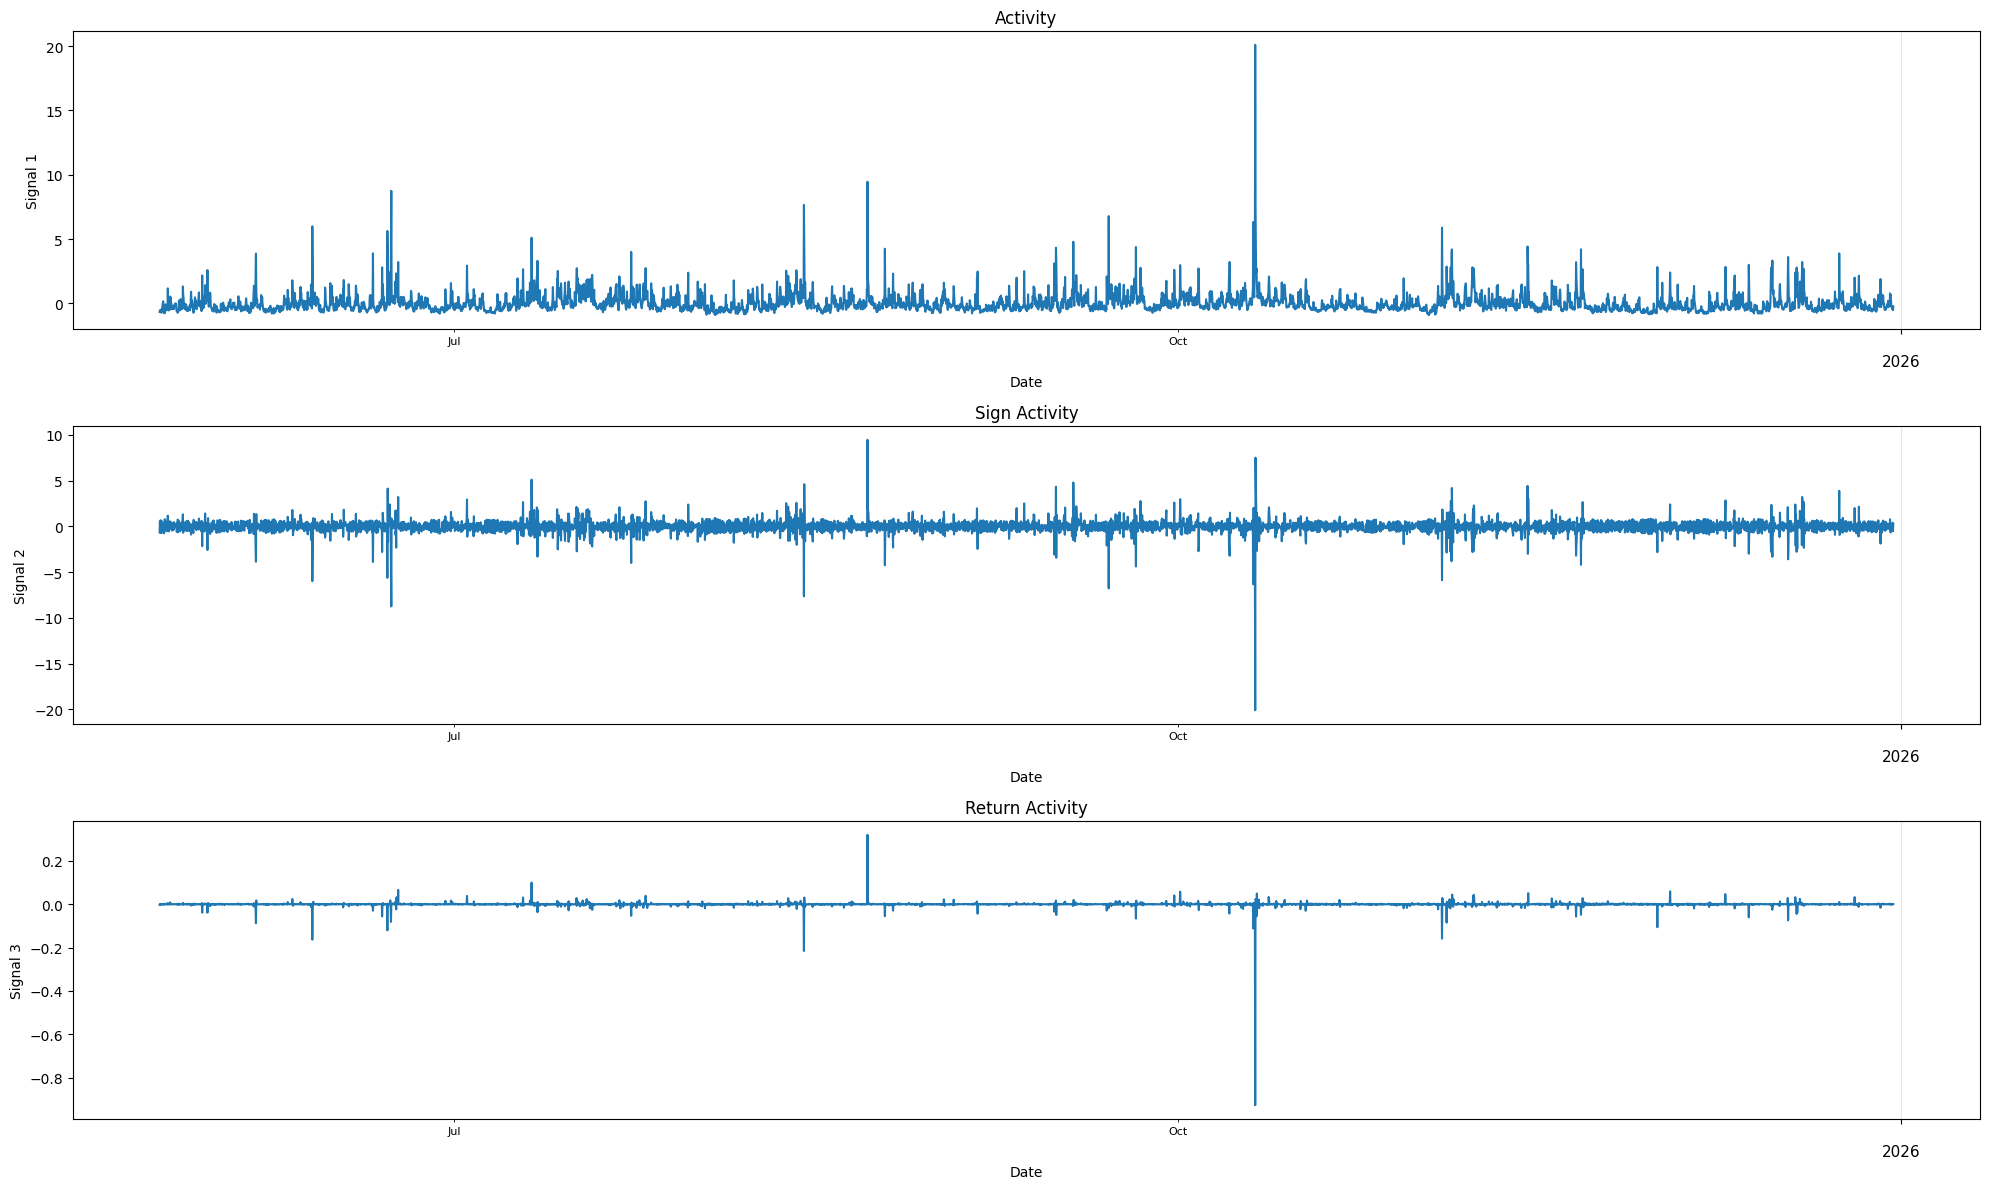

In [19]:
data=get_prices("1h", "2025-01-01", "2025-12-31",10)

In [ ]:
get_all_klines("BTCUSDT", "1h", "2020-01-01", "2020-12-31")

In [ ]:
get_all_klines("BTCUSDT", "1h", "2021-01-01", "2021-12-31")

In [ ]:
get_all_klines("BTCUSDT", "1h", "2022-01-01", "2022-12-31")

In [ ]:
get_all_klines("BTCUSDT", "1h", "2023-01-01", "2023-12-31")

In [ ]:
get_all_klines("BTCUSDT", "1h", "2024-01-01", "2024-12-31")

In [ ]:
get_all_klines("BTCUSDT", "1h", "2025-01-01", "2025-12-31")

In [ ]:
get_all_klines("BTCUSDT", "1h", "2026-01-01", "2026-09-01")

In [ ]:
get_all_klines("BTCUSDT", "1h", "2009-01-01", "2026-09-01")

Using existing data: crypto_1000_1d_2017-01-01_2026-09-09_vol.pk


C:\Users\parra\AppData\Local\Temp\ipykernel_12424\2852550917.py:5: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  ret_data=px.pct_change()


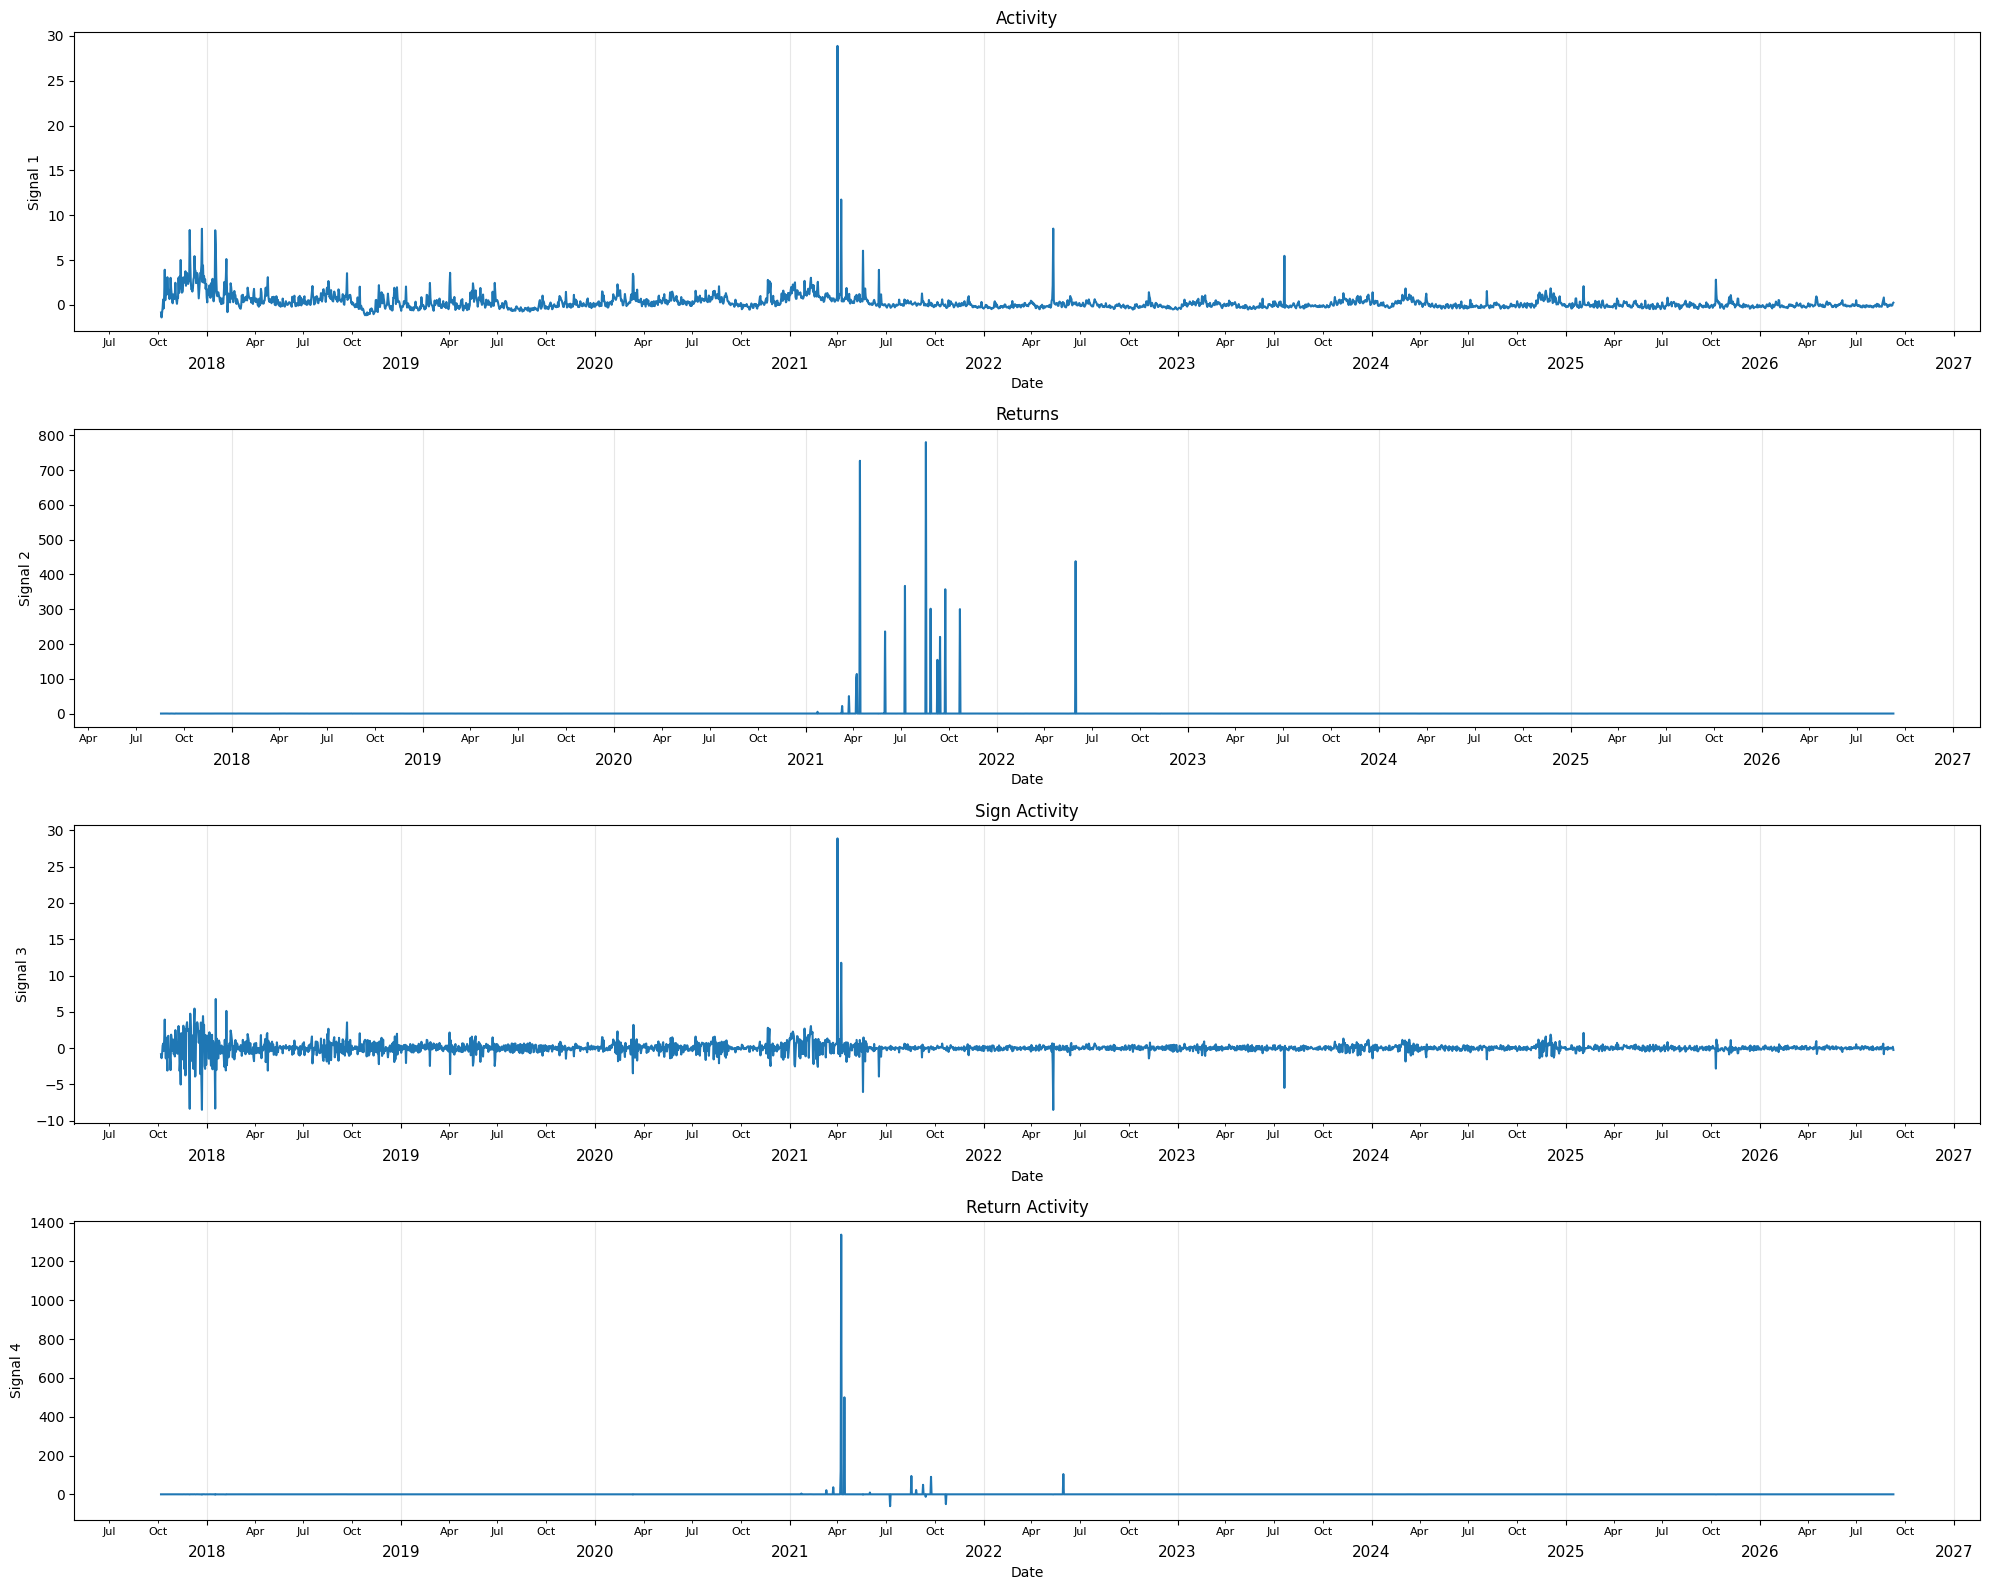

,USDCUSDT,BTCUSDT,ETHUSDT,ZECUSDT,SOLUSDT,XRPUSDT,USD1USDT,BNBUSDT,NEARUSDT,DOGEUSDT,...,XLMDOWNUSDT,USTUSDT,RGTUSDT,ANYUSDT,NANOUSDT,USDSBUSDT,AAVEUPUSDT,AAVEDOWNUSDT,SUSDUSDT,BCCUSDT
open_time,,,,,,,,,,,,,,,,,,,,,
2017-08-17 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-18 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-19 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-20 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-08-21 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-05 00:00:00+00:00,0.528556,-0.879413,-1.138790,-0.424454,-1.013131,-0.592901,0.264111,0.594770,0.600039,0.393787,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-06 00:00:00+00:00,0.784446,-0.901039,-0.830726,0.141926,-0.323497,-0.625453,0.231583,-0.204526,1.514362,-0.080707,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-07 00:00:00+00:00,0.521418,-0.733898,-0.693955,-0.275085,-0.624793,-0.140203,0.222543,-0.484200,0.236605,-0.328271,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
activity("1d", "2017-01-01", "2026-09-09",1000)